# Fully coupled poromechanics: consolidation of a poroelastic column

This demo simulates the consolidation of a saturated poroelastic column by solving
the fully coupled hydro-mechanical problem: the displacement field $u$ and the
pore pressure field $p$ are treated as simultaneous unknowns, and the constitutive
model is a coupled multiphysics behavior. Time is integrated with
[`diffrax`](https://github.com/patrick-kidger/diffrax), and the result is validated
against the analytical Terzaghi solution.


## A multiphysics constitutive model

Classical mechanics behaviors map one input to one output, typically strain to stress,
`constitutive_update(eps, state, dt)`. Poromechanics extends this structure to two
different fields. The material responds to the strain $\beps$ and the pore
pressure $p$, and returns two conjugate quantities, the total stress $\bsig$
and the variation of fluid mass content $m$ (per unit reference
volume). Writing $\zeta = m/\rho_f^0$ for the (dimensionless) Lagrangian
variation of fluid content, the behavior is:

$$
(\bsig,\ \zeta), \text{new state} \;=\; \texttt{constitutive_update}\big((\beps,\ p),\
\text{state},\ \mathrm{d}t\big).
$$

For linear isotropic (Biot) poroelasticity these read

$$
\bsig = \mathbb{C}:\beps - b\,p\,\bI,
\qquad
\zeta = b\,\mathrm{tr}\,\beps + \frac{p}{M},
$$

where $\mathbb{C}$ is the drained stiffness, $b$ is the Biot coefficient and $M$
the Biot modulus. Both relations derive from a single quadratic free energy, so
the coupling is symmetric: the *same* $b$ links pressure to stress and strain to
fluid content. The cross terms $-b\,p\,\bI$ and $b\,\mathrm{tr}\,\beps$ are the
hydro-mechanical coupling. The two physics decouple only in the case $b=0$.

In `jaxmat`, such a behavior starts by declaring the variables it exchanges with
`make_physics`: the *gradients* $(\beps, p)$ given as inputs, and their conjugate *fluxes*
$(\bsig, \zeta)$ computed by the behavior. The declaration generates the corresponding state
class, so that a `MultiphysicsBehavior` only implements the constitutive relations, in its
`response` method. Packing the inputs and outputs and storing them in the new state are done
automatically. The names and conventions are those of the formulation at hand: here the
pore pressure is `p` and its conjugate flux the fluid content `zeta`.

Here, we will focus on a fully coupled treatment of consolidation: the multiphysics
`constitutive_update` is evaluated at every spatial node for both $\beps$ and $p$
and the coupled displacement-pressure system is solved as such.

In [1]:
import diffrax
import equinox as eqx
import jax
import jax.numpy as jnp
import lineax as lx
import matplotlib.pyplot as plt
import optimistix as optx
from matplotlib import cm

import jaxmat.materials as jm
from jaxmat.parameters import parameter
from jaxmat.state import make_physics
from jaxmat.tensors import IsotropicTensor4, SymmetricTensor2

In [2]:
POROMECHANICS = make_physics(
    "Poromechanics",
    gradients={"strain": SymmetricTensor2, "p": 0.0},
    fluxes={"stress": SymmetricTensor2, "zeta": 0.0},
)


class PoroElastic(jm.MultiphysicsBehavior):
    """Linear isotropic Biot poroelasticity: (eps, p) -> (sigma, zeta)."""

    physics = POROMECHANICS
    K: jax.Array = parameter()  # drained bulk modulus
    mu: jax.Array = parameter()  # shear modulus
    b: jax.Array = parameter()  # Biot coefficient
    M: jax.Array = parameter()  # Biot modulus

    @property
    def C(self):
        return IsotropicTensor4(kappa=self.K, mu=self.mu)

    def response(self, x, state, dt):
        sig = self.C @ x.strain - self.b * x.p * SymmetricTensor2.identity()
        zeta = self.b * x.strain.tr + x.p / self.M
        return (sig, zeta), None  # no internal state variables


mat = PoroElastic(K=10e3, mu=6e3, b=0.9, M=8e3)  # MPa
# The behavior is linear, without internal variables: the same initial state serves everywhere.
state0 = mat.init_state()
E_oed = mat.K + 4 * mat.mu / 3  # oedometer modulus (for reference/validation only)

## Governing equations

We consider a column of height $H$ under oedometer conditions (uniaxial strain: only
the vertical strain $\varepsilon_{zz}=\partial_z u$ is nonzero). Two balance laws are
solved together:

* **Quasi-static mechanical equilibrium** (algebraic in time):

  $$\displaystyle \frac{\partial \sigma_{zz}}{\partial z} = 0,$$

  with a prescribed vertical total stress $\sigma_{zz}=\sigma_\text{top}$
  at the top and a fixed base $u=0$ at the bottom.

* **Fluid mass balance** with Darcy flow (dynamic):

  $$\displaystyle \frac{\partial \zeta}{\partial t}
  = \frac{k}{\gamma_w}\frac{\partial^2 p}{\partial z^2},$$

  with a drained top ($p=0$) and an impermeable bottom ($\partial_z p = 0$).

The coupling runs both ways: $\sigma_{zz}$ depends on $p$ through the constitutive
law, and $\zeta$ (whose rate drives the fluid equation) depends on the strain, i.e.
on $u$. The genuinely time-evolving quantity is the fluid content $\zeta$; given
$\zeta$, the pair $(u,p)$ is fixed by the mechanical equilibrium together with the
constitutive relation. This is a differential-algebraic system.

In [3]:
N = 101
H = 1.0
z = jnp.linspace(0.0, H, N)
dz = z[1] - z[0]
k_cond, gamma_w = 1e-9, 9.81e-3  # conductivity, fluid specific weight
sig_top = -10.0  # applied vertical total stress [MPa] (compression)
c = k_cond / gamma_w


def grad_z(f):
    """Vertical derivative by central / one-sided finite differences."""
    g = jnp.zeros(N)
    g = g.at[1:-1].set((f[2:] - f[:-2]) / (2 * dz))
    g = g.at[0].set((f[1] - f[0]) / dz)
    g = g.at[-1].set((f[-1] - f[-2]) / dz)
    return g


def constitutive_update_1D(eps_zz, p):
    """Evaluate the multiphysics behavior (eps, p) -> (sigma_zz, zeta) at a given node."""
    eps = SymmetricTensor2(array=jnp.array([0.0, 0.0, eps_zz, 0.0, 0.0, 0.0]))
    (sig, zeta), _ = mat.constitutive_update((eps, p), state0, 1.0)
    return sig.tensor[2, 2], zeta


# batch multiphysics behavior evaluation across all node
batched_constitutive_update = eqx.filter_vmap(constitutive_update_1D)

## Recovering the coupled $(u,p)$ state

The dynamic variable of the problem is the fluid content field $\zeta$. At any instant
we must recover the pair of fields $(u, p)$ consistent with that $\zeta$. Rather than
eliminate the pressure analytically (which could be possible though in this linear case),
we solve for both $u$ and $p$ monolithically from a coupled residual with two blocks:

* a mechanical block enforcing equilibrium $\partial_z\sigma_{zz}=0$ (with the
  applied top stress and the fixed base), and
* a constitutive/hydraulic block enforcing that the fluid content produced by the
  current $(u,p)$ matches the imposed $\zeta$, i.e. $\zeta(u,p)-\zeta = 0$, with the
  drained condition $p_0=0$ substituted at the top node.
Every residual evaluation calls the multiphysics `constitutive_update` at every node,
so the two physics are coupled inside a single Newton solve.

In [4]:
def recover_up(zeta):
    """Solve mechanical equilibrium for (u, p) given the fluid content zeta."""

    def residual(y, args):
        u, p = y
        eps_zz = grad_z(u)
        sig, zeta_ = batched_constitutive_update(eps_zz, p)
        rsig = jnp.zeros(N)
        rsig = rsig.at[1:-1].set((sig[2:] - sig[:-2]) / (2 * dz))  # equilibrium
        rsig = rsig.at[0].set(sig[0] - sig_top)  # applied top stress
        rsig = rsig.at[-1].set(u[-1])  # fixed base
        rzeta = zeta - zeta_  # enforce fluid content value
        rzeta = rzeta.at[0].set(p[0])  # enforce p=0
        return rsig, rzeta

    y0 = jnp.zeros(N), jnp.zeros(N)
    u, p = optx.root_find(
        residual,
        optx.Newton(rtol=1e-6, atol=1e-6, linear_solver=lx.AutoLinearSolver(well_posed=True)),
        y0,
        max_steps=50,
        throw=False,
    ).value
    return u, p

## Time integration with `diffrax`

The dynamic variable is the fluid content $\zeta$. Its rate is the Darcy flux of the
recovered pressure, $\partial_t\zeta = c\,\partial_z^2 p$. At each right-hand-side
evaluation `diffrax` calls `recover_up`, which solves the coupled mechanics equilibrium,
i.e. finding the displacement and pressure fields in equilibrium with a given fluid content.
The semi-discretized diffusion ODE is stiff, so we use the `ImplicitEuler` solver.

The initial condition is the undrained response: at $t=0^+$ the load is applied
with no fluid yet exchanged, i.e. $\zeta = 0$ everywhere, which already induces a
nonzero pore pressure through the coupling.

In [5]:
def vector_field(t, zeta, args):
    _, p = recover_up(zeta)
    lap = jnp.zeros(N)
    lap = lap.at[1:-1].set((p[:-2] - 2 * p[1:-1] + p[2:]) / dz**2)
    lap = lap.at[-1].set((2 * p[-2] - 2 * p[-1]) / dz**2)  # impermeable bottom
    dzeta_dt = c * lap
    return dzeta_dt


zeta0 = jnp.zeros(N)  # undrained initial state
t_end = 2000.0
ts = jnp.linspace(0.0, t_end, 101)

sol = diffrax.diffeqsolve(
    diffrax.ODETerm(vector_field),
    diffrax.ImplicitEuler(),
    t0=0.0,
    t1=t_end,
    dt0=1.0,
    y0=zeta0,
    saveat=diffrax.SaveAt(ts=ts),
    stepsize_controller=diffrax.PIDController(rtol=1e-6, atol=1e-9),
)

# recover the full (u, p) history from the fluid-content trajectory
U_hist, P_hist = jax.vmap(recover_up)(sol.ys)

## Validation and the undrained-to-drained transition

The degree of consolidation $U(t) = 1 - \bar p(t)/p_0$ measures how much of the
initial excess pore pressure has dissipated. We compare it to the Terzaghi series in
terms of the time factor $T_v = c_v t/H^2$, where $c_v = c/S$ and
$S = b^2/E_\text{oed} + 1/M$ is the oedometer storativity (used here only to
non-dimensionalize the reference solution). The initial excess pressure is
$p_0 = -b M\,\sigma_\text{top}/(E_\text{oed}+b^2 M)$.

In [6]:
S = mat.b**2 / E_oed + 1 / mat.M
c_v = c / S
Tv = c_v * ts / H**2
p0 = -sig_top * mat.b * mat.M / (E_oed + mat.b**2 * mat.M)

U = 1.0 - jnp.trapezoid(P_hist, z, axis=1) / (p0 * H)


def U_terzaghi(Tv, nterms=200):
    n = jnp.arange(nterms)
    Mn = (2 * n + 1) * jnp.pi / 2
    return 1.0 - jnp.sum((2 / Mn**2)[None, :] * jnp.exp(-(Mn**2)[None, :] * Tv[:, None]), axis=1)


mask = Tv > 0.02  # early-time front is under-resolved on a fixed grid
print(f"initial (undrained) p0[mid] = {float(P_hist[0][N // 2]):.4f}  (expected {float(p0):.4f})")
print(
    f"max |U_coupled - U_Terzaghi| = {float(jnp.max(jnp.abs(U[mask] - U_terzaghi(Tv[mask])))):.2e}"
)

initial (undrained) p0[mid] = 2.9412  (expected 2.9412)
max |U_coupled - U_Terzaghi| = 3.84e-04


Because both fields are solved, we can read the settlement directly from the
displacement history. We clearly recover the consolidation phenomenon: the column continues to
settle after the instantaneous undrained response, as the pore pressure dissipates
and the load transfers to the skeleton.

In [7]:
settlement = U_hist[:, 0]  # top displacement
print(f"undrained settlement (t=0+) : {float(settlement[0]) * 1e3:.4f} mm")
print(f"drained settlement  (t=inf) : {float(settlement[-1]) * 1e3:.4f} mm")
print(f"consolidation increment     : {float(settlement[-1] - settlement[0]) * 1e3:.4f} mm")

undrained settlement (t=0+) : 0.4100 mm
drained settlement  (t=inf) : 0.5493 mm
consolidation increment     : 0.1394 mm


## Results

We first show the pore pressure profile at different time steps.
The excess pore pressure dissipates from the drained top: at $t=0^+$ the pressure is
uniform at $p_0$ over the depth (the undrained response), and it relaxes towards zero
from the top down as fluid drains, the front penetrating deeper with increasing time
factor $T_v$.

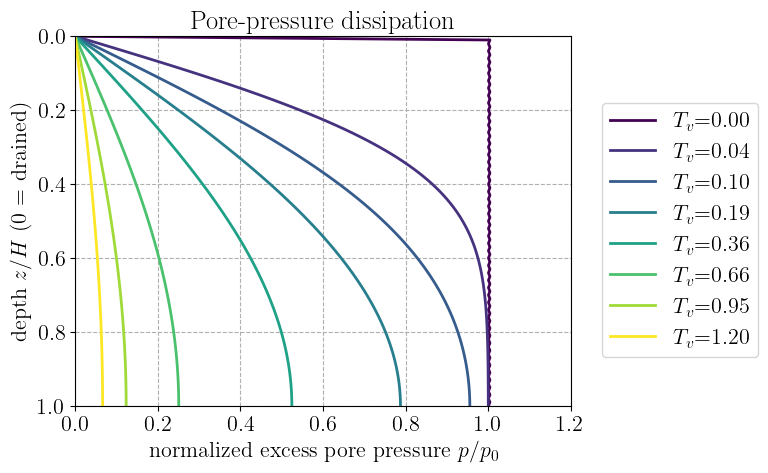

In [13]:
# pore-pressure isochrones
plt.figure()
idx = [0, 3, 8, 16, 30, 55, 79, 100]
colors = cm.viridis(jnp.linspace(0.0, 1.0, len(idx)))
for i, col in zip(idx, colors):
    plt.plot(P_hist[i] / p0, z / H, color=col, label=f"$T_v$={float(Tv[i]):.2f}")
plt.xlabel("normalized excess pore pressure $p/p_0$")
plt.ylabel("depth $z/H$ (0 = drained)")
plt.title("Pore-pressure dissipation")
plt.gca().invert_yaxis()
plt.legend()
plt.show()

The consolidation curve collapses onto the Terzaghi series when
plotted against $T_v$, confirming that the fully coupled $(u,p)$
solve reproduces the classical solution to within the spatial
discretization error (largest at very early times, where the pressure
front near the drained boundary is sharpest).

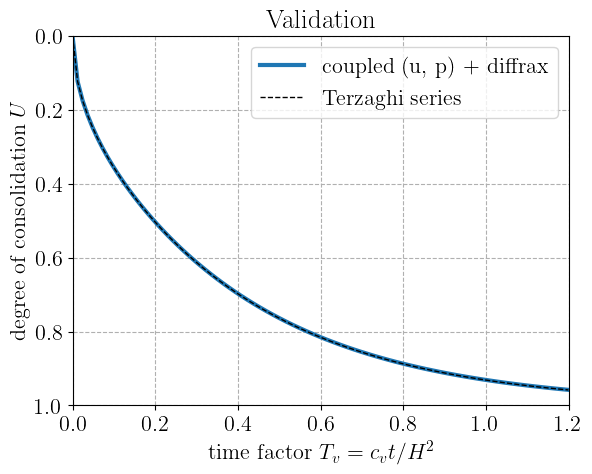

In [9]:
# consolidation curve vs Terzaghi
plt.figure()
plt.plot(Tv, U, "C0", lw=3, label="coupled (u, p) + diffrax")
plt.plot(Tv, U_terzaghi(Tv), "k--", lw=1.0, label="Terzaghi series")
plt.xlabel("time factor $T_v = c_v t / H^2$")
plt.ylabel("degree of consolidation $U$")
plt.title("Validation")
plt.legend()
plt.gca().invert_yaxis()
plt.show()

Finally, the settlement history exhibits an instantaneous undrained
settlement upon loading, followed by a slow time-dependent increase
(the consolidation settlement) as the excess pressure dissipates and the
load is progressively transferred from the pore fluid to the solid skeleton.

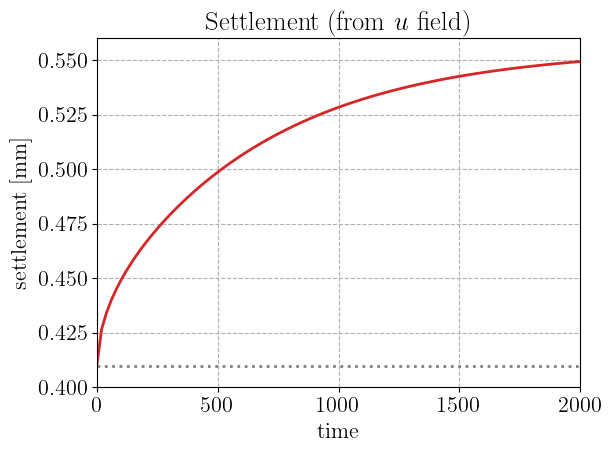

In [10]:
# settlement history (from the displacement field)
plt.figure()
plt.plot(ts, settlement * 1e3, "C3")
plt.axhline(settlement[0] * 1e3, ls=":", color="gray", label="undrained")
plt.xlabel("time")
plt.ylabel("settlement [mm]")
plt.title("Settlement (from $u$ field)")
plt.tight_layout()
plt.show()

## Discussion

This demo presents a coupled hydro-mechanical solver: displacement and pressure are
carried as separate fields, the multiphysics `constitutive_update((eps, p))` is
evaluated at every node, and the two balance laws are satisfied simultaneously.
In one dimension with a linear material the result must coincide with Terzaghi,
which is exactly the validation we obtain. The above solver carries over unchanged
to the case of a nonlinear or finite-strain skeleton, a pressure-dependent
permeability, etc.